In [2]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [3]:
df_timeseries = pd.read_csv(r"D:\Aswini\EDA\EV_charging\evcharging\Data\EVChargingRecords_Features.csv")

In [4]:
df_timeseries.columns

Index(['Unnamed: 0', 'UserID', 'ChargerID', 'ChargerCompany', 'Location',
       'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime',
       'StartDatetime', 'EndDatetime', 'Duration', 'Demand',
       'Duration_seconds', 'Duration_minutes', 'Duration_hours', 'is_anomaly',
       'start day', 'start month', 'end day', 'end month', 'year',
       'day_of_week', 'is_weekend', 'time_of_day', 'prev_sessions',
       'HighDemand'],
      dtype='str')

In [5]:
df_timeseries['StartDatetime'] = pd.to_datetime(df_timeseries['StartDatetime'])
df_timeseries.set_index('StartDatetime', inplace=True)

In [61]:
# Daily aggregation (uppercase 'D' is fine)
df_daily = df_timeseries['Demand'].resample('D').sum()


In [8]:
# aggregation by time of the day like morning afternoon evening and night
daily_period_demand = (
    df_timeseries
    .groupby([df_timeseries.index.date, df_timeseries['time_of_day']])['Demand']
    .sum()
    .unstack(fill_value=0)   
)

print(daily_period_demand.head())


time_of_day  Afternoon  Evening  Morning  Night
2021-09-30       27.68   551.51     0.00   0.00
2021-10-01      919.69   899.81   516.03  98.88
2021-10-02      699.33   920.91   351.87  94.63
2021-10-03      559.93   865.44   367.09  94.69
2021-10-04      552.54   714.92   416.39  84.81


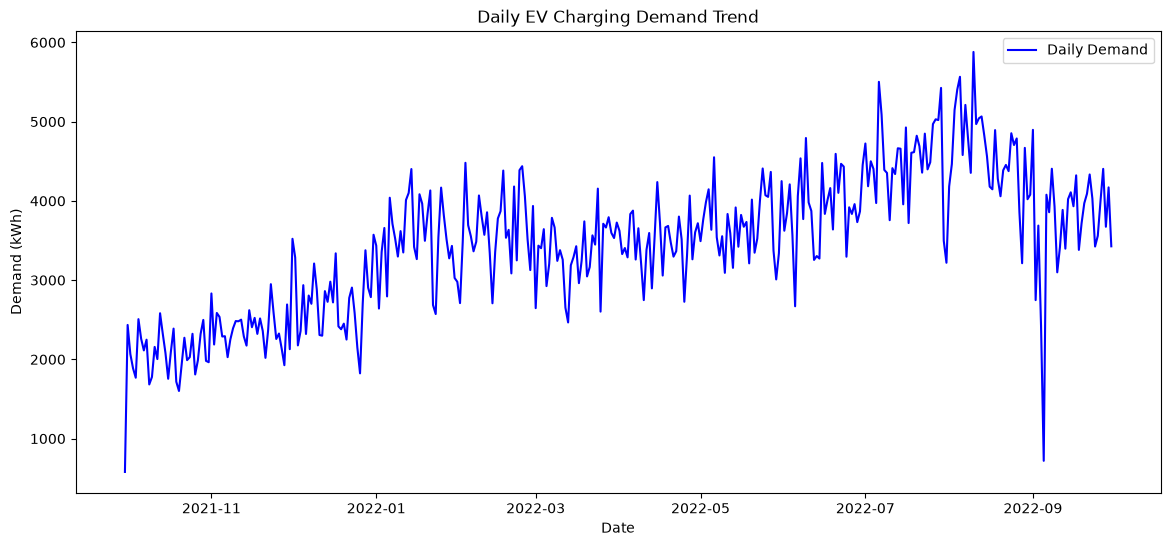

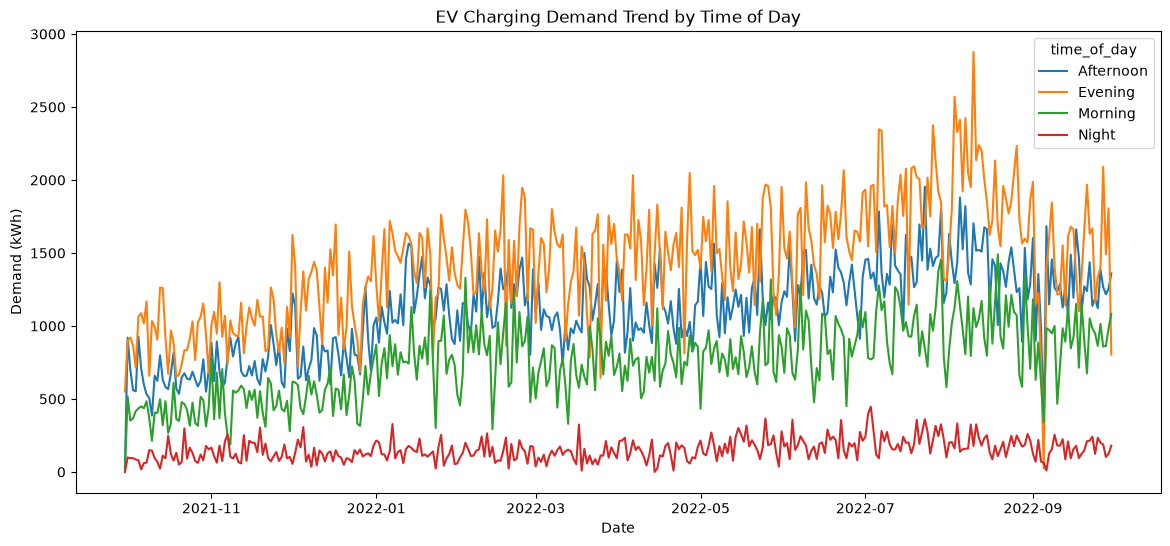

In [9]:
# Plot daily demand
import matplotlib.pyplot as plt
plt.figure(figsize=(14,6))
plt.plot(df_daily.index, df_daily, label='Daily Demand', color='blue')
plt.title("Daily EV Charging Demand Trend")
plt.xlabel("Date")
plt.ylabel("Demand (kWh)")
plt.legend()
plt.show()

# Plot each period’s trend
daily_period_demand.plot(figsize=(14,6))
plt.title("EV Charging Demand Trend by Time of Day")
plt.xlabel("Date")
plt.ylabel("Demand (kWh)")
plt.show()


In [10]:
from statsmodels.tsa.stattools import adfuller

# Stationarity check for overall daily demand
result = adfuller(df_daily.dropna(), result_object=True)
print("Stationarity check for daily demand")
print("ADF Statistic:", result.statistic)
print("p-value:", result.pvalue)

# Stationarity check for each time_of_day demand
print("\nStationarity check for time-of-day demand")
for col in daily_period_demand.columns:
    result = adfuller(daily_period_demand[col].dropna(), result_object=True)
    print(f"{col} -> ADF Statistic: {result.statistic}, p-value: {result.pvalue}")


Stationarity check for daily demand
ADF Statistic: -1.8725163651562768
p-value: 0.34509865323851385

Stationarity check for time-of-day demand
Afternoon -> ADF Statistic: -2.171993233598712, p-value: 0.2165668381584312
Evening -> ADF Statistic: -2.12310327513595, p-value: 0.23532669847737658
Morning -> ADF Statistic: -1.783151134896458, p-value: 0.3888581869630381
Night -> ADF Statistic: -2.4645213167032534, p-value: 0.124346995136698


## Stationarity Analysis Using Augmented Dickey-Fuller (ADF) Test

| Time Series | ADF Statistic | p-value | Stationary? |
|------------|--------------:|---------:|:-----------:|
| Daily Demand | -1.8725 | 0.3451 | ❌ No |
| Morning Demand | -1.7832 | 0.3889 | ❌ No |
| Afternoon Demand | -2.1720 | 0.2166 | ❌ No |
| Evening Demand | -2.1231 | 0.2353 | ❌ No |
| Night Demand | -2.4645 | 0.1243 | ❌ No |

### Interpretation

The Augmented Dickey-Fuller (ADF) test was conducted to assess the stationarity of EV charging demand across the overall daily series and different time-of-day periods. For all series, the p-values were greater than the significance level of 0.05, indicating a failure to reject the null hypothesis of a unit root.

Consequently, the daily demand series and all time-of-day demand series (Morning, Afternoon, Evening, and Night) are **non-stationary**, suggesting the presence of underlying trends, seasonality, or other temporal patterns in EV charging demand.


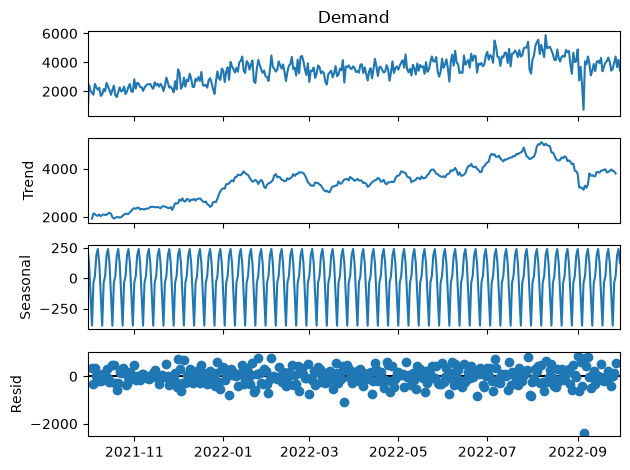

In [11]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Decompose daily demand series
decomp = seasonal_decompose(df_daily, model='additive', period=7)  # weekly cycle assumed
decomp.plot()
plt.show()


In [24]:
# df_daily is a Series indexed by Date

train_size = int(len(df_daily) * 0.8)

train = df_daily.iloc[:train_size]
test = df_daily.iloc[train_size:]

print("Train period:", train.index.min(), "to", train.index.max())
print("Test period:", test.index.min(), "to", test.index.max())

Train period: 2021-09-30 00:00:00 to 2022-07-18 00:00:00
Test period: 2022-07-19 00:00:00 to 2022-09-30 00:00:00


In [25]:
window = 7

history = list(train)
predictions = []

for t in range(len(test)):
    forecast = sum(history[-window:]) / window
    predictions.append(forecast)

    # Add actual observation to history
    history.append(test.iloc[t])


In [47]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

rmse = np.sqrt(mean_squared_error(test, predictions))
mae = mean_absolute_error(test, predictions)
print("Moving Average")
print("RMSE:", rmse)
print("MAE:", mae)

Moving Average
RMSE: 686.953199459766
MAE: 502.51170366795367


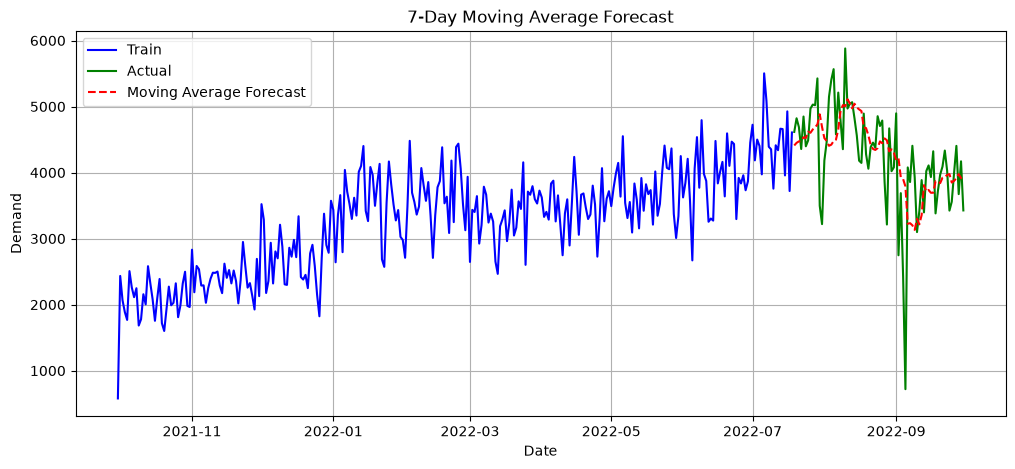

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(train.index, train,
         label='Train',
         color='blue')

plt.plot(test.index, test,
         label='Actual',
         color='green')

plt.plot(test.index, predictions,
         label='Moving Average Forecast',
         color='red',
         linestyle='--')

plt.title('7-Day Moving Average Forecast')
plt.xlabel('Date')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)

plt.show()

In [28]:
window = 7

forecast_ma = df_daily.iloc[-window:].mean()

future_dates = pd.date_range(
    start=df_daily.index[-1] + pd.Timedelta(days=1),
    periods=7,
    freq='D'
)

future_forecast = pd.Series(
    [forecast_ma] * 7,
    index=future_dates
)

print(future_forecast)

2022-10-01    3807.592857
2022-10-02    3807.592857
2022-10-03    3807.592857
2022-10-04    3807.592857
2022-10-05    3807.592857
2022-10-06    3807.592857
2022-10-07    3807.592857
Freq: D, dtype: float64


In [29]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Train model
model_es = SimpleExpSmoothing(
    train,
    initialization_method="heuristic"
).fit(
    smoothing_level=0.2,
    optimized=False
)

In [30]:
# Forecast same length as test set
predictions_es = model_es.forecast(len(test))

print(predictions_es.head())

2022-07-19    4383.738571
2022-07-20    4383.738571
2022-07-21    4383.738571
2022-07-22    4383.738571
2022-07-23    4383.738571
Freq: D, dtype: float64


In [48]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

rmse = np.sqrt(mean_squared_error(test, predictions_es))
mae = mean_absolute_error(test, predictions_es)
print("ExponentialSmoothing")
print("RMSE:", rmse)
print("MAE:", mae)

ExponentialSmoothing
RMSE: 789.0967780690439
MAE: 569.0655212362823


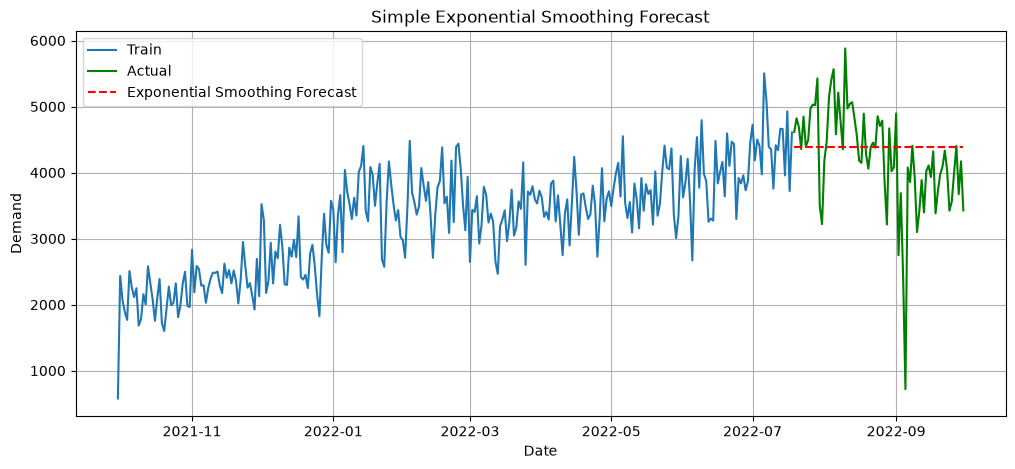

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(train.index, train, label='Train')
plt.plot(test.index, test, label='Actual', color='green')
plt.plot(test.index, predictions_es,
         label='Exponential Smoothing Forecast',
         color='red',
         linestyle='--')

plt.title('Simple Exponential Smoothing Forecast')
plt.xlabel('Date')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)
plt.show()

In [34]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

final_model = SimpleExpSmoothing(
    df_daily,
    initialization_method="heuristic"
).fit(
    smoothing_level=0.2,
    optimized=False
)

forecast_es = final_model.forecast(7)

print("Next 7-Day Forecast:")
print(forecast_es)

Next 7-Day Forecast:
2022-10-01    3847.332331
2022-10-02    3847.332331
2022-10-03    3847.332331
2022-10-04    3847.332331
2022-10-05    3847.332331
2022-10-06    3847.332331
2022-10-07    3847.332331
Freq: D, dtype: float64


In [49]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Chronological split
train_size = int(len(df_daily) * 0.8)

train = df_daily.iloc[:train_size]
test = df_daily.iloc[train_size:]

# Fit Holt-Winters on training data only
hw_model = ExponentialSmoothing(
    train,
    trend='add',
    seasonal='add',
    seasonal_periods=7
).fit()

# Forecast test period
predictions_hw = hw_model.forecast(len(test))

# Evaluation
rmse = np.sqrt(mean_squared_error(test, predictions_hw))
mae = mean_absolute_error(test, predictions_hw)
print("Holt Winters")
print("RMSE:", rmse)
print("MAE:", mae)

Holt Winters
RMSE: 1023.4535781032781
MAE: 786.2964876328034


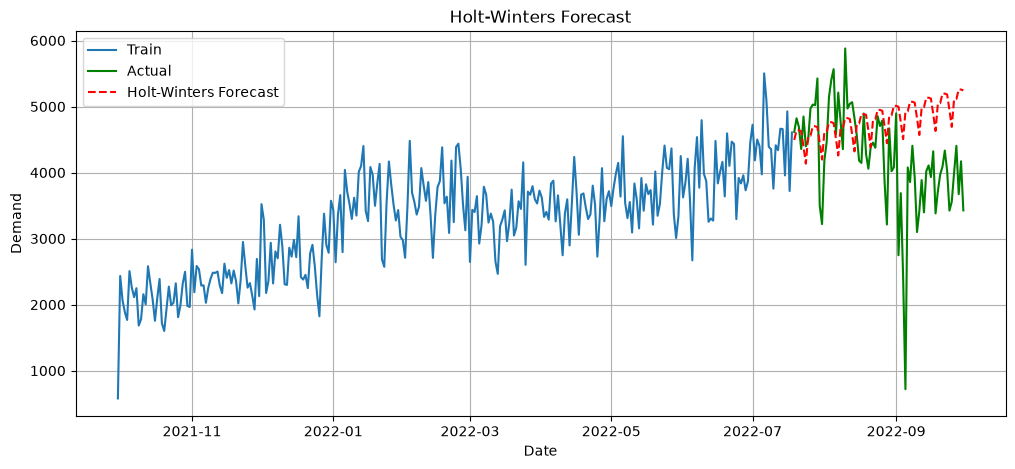

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(train.index, train, label='Train')
plt.plot(test.index, test, label='Actual', color='green')
plt.plot(test.index, predictions_hw,
         label='Holt-Winters Forecast',
         color='red',
         linestyle='--')

plt.title('Holt-Winters Forecast')
plt.xlabel('Date')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)

plt.show()

In [37]:
final_hw_model = ExponentialSmoothing(
    df_daily,
    trend='add',
    seasonal='add',
    seasonal_periods=7
).fit()

forecast_hw = final_hw_model.forecast(10)

print("Holt-Winters Forecast (Next 10 Days):")
print(forecast_hw)

Holt-Winters Forecast (Next 10 Days):
2022-10-01    3678.744328
2022-10-02    3426.668012
2022-10-03    3791.116917
2022-10-04    3850.493555
2022-10-05    4016.626254
2022-10-06    4054.337668
2022-10-07    3964.659993
2022-10-08    3715.764500
2022-10-09    3463.688184
2022-10-10    3828.137089
Freq: D, dtype: float64


In [51]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    ExponentialSmoothing
)

# Forecast horizon
horizon = 7

all_forecasts = {}
all_metrics = []

for col in daily_period_demand.columns:

    series = daily_period_demand[col].dropna()

    # ==========================
    # Train-Test Split
    # ==========================
    train_size = int(len(series) * 0.8)

    train = series.iloc[:train_size]
    test = series.iloc[train_size:]

    # ==========================
    # Moving Average Evaluation
    # ==========================
    history = list(train)
    ma_predictions = []

    for t in range(len(test)):
        forecast = np.mean(history[-7:])
        ma_predictions.append(forecast)
        history.append(test.iloc[t])

    ma_rmse = np.sqrt(mean_squared_error(test, ma_predictions))
    ma_mae = mean_absolute_error(test, ma_predictions)

    # ==========================
    # Exponential Smoothing
    # ==========================
    es_model = SimpleExpSmoothing(
        train,
        initialization_method="heuristic"
    ).fit(optimized=True)

    es_predictions = es_model.forecast(len(test))

    es_rmse = np.sqrt(mean_squared_error(test, es_predictions))
    es_mae = mean_absolute_error(test, es_predictions)

    # ==========================
    # Holt-Winters
    # ==========================
    try:
        hw_model = ExponentialSmoothing(
            train,
            trend='add',
            seasonal='add',
            seasonal_periods=7
        ).fit()

        hw_predictions = hw_model.forecast(len(test))

        hw_rmse = np.sqrt(mean_squared_error(test, hw_predictions))
        hw_mae = mean_absolute_error(test, hw_predictions)

    except:
        hw_rmse = np.nan
        hw_mae = np.nan

    # ==========================
    # Store Metrics
    # ==========================
    all_metrics.append({
        'Period': col,

        'MA_RMSE': ma_rmse,
        'MA_MAE': ma_mae,

        'ES_RMSE': es_rmse,
        'ES_MAE': es_mae,

        'HW_RMSE': hw_rmse,
        'HW_MAE': hw_mae
    })

    # ==========================
    # Refit on Full Data
    # For Future Forecasting
    # ==========================

    future_dates = pd.date_range(
        start=series.index[-1] + pd.Timedelta(days=1),
        periods=horizon,
        freq='D'
    )

    # Moving Average Forecast
    ma_value = series.iloc[-7:].mean()

    ma_forecast = pd.Series(
        [ma_value] * horizon,
        index=future_dates
    )

    # Exponential Smoothing Forecast
    final_es = SimpleExpSmoothing(
        series,
        initialization_method="heuristic"
    ).fit(optimized=True)

    es_forecast = final_es.forecast(horizon)

    # Holt-Winters Forecast
    try:
        final_hw = ExponentialSmoothing(
            series,
            trend='add',
            seasonal='add',
            seasonal_periods=7
        ).fit()

        hw_forecast = final_hw.forecast(horizon)

    except:
        hw_forecast = pd.Series(
            [np.nan] * horizon,
            index=future_dates
        )

    # Store Forecasts
    forecast_df = pd.DataFrame({
        'Moving Average': ma_forecast,
        'Exponential Smoothing': es_forecast,
        'Holt-Winters': hw_forecast
    })

    all_forecasts[col] = forecast_df

# =====================================
# Metrics Summary
# =====================================

metrics_df = pd.DataFrame(all_metrics)

print("Model Performance")
print(metrics_df)

# =====================================
# Forecast Results
# =====================================

for col, forecast_df in all_forecasts.items():

    print(f"\n{'='*50}")
    print(f"Forecasts for {col}")
    print(f"{'='*50}")

    print(forecast_df.round(2))

Model Performance
      Period     MA_RMSE      MA_MAE     ES_RMSE      ES_MAE     HW_RMSE  \
0  Afternoon  243.940769  178.455676  253.892337  188.584946  326.244471   
1    Evening  386.823951  299.609903  447.453357  336.866497  509.322355   
2    Morning  224.053864  179.027104  219.550909  168.969491  247.016315   
3      Night   73.780602   59.616486   73.437481   58.036915   83.011850   

       HW_MAE  
0  249.849816  
1  394.752060  
2  197.512899  
3   66.762984  

Forecasts for Afternoon
            Moving Average  Exponential Smoothing  Holt-Winters
2022-10-01         1256.48                1273.47       1308.92
2022-10-02         1256.48                1273.47       1224.04
2022-10-03         1256.48                1273.47       1311.78
2022-10-04         1256.48                1273.47       1278.62
2022-10-05         1256.48                1273.47       1304.55
2022-10-06         1256.48                1273.47       1335.16
2022-10-07         1256.48                1273.4

In [52]:
metrics_df['Best_Model'] = metrics_df[
    ['MA_RMSE','ES_RMSE','HW_RMSE']
].idxmin(axis=1)

print(metrics_df[
    ['Period','Best_Model']
])

      Period Best_Model
0  Afternoon    MA_RMSE
1    Evening    MA_RMSE
2    Morning    ES_RMSE
3      Night    ES_RMSE


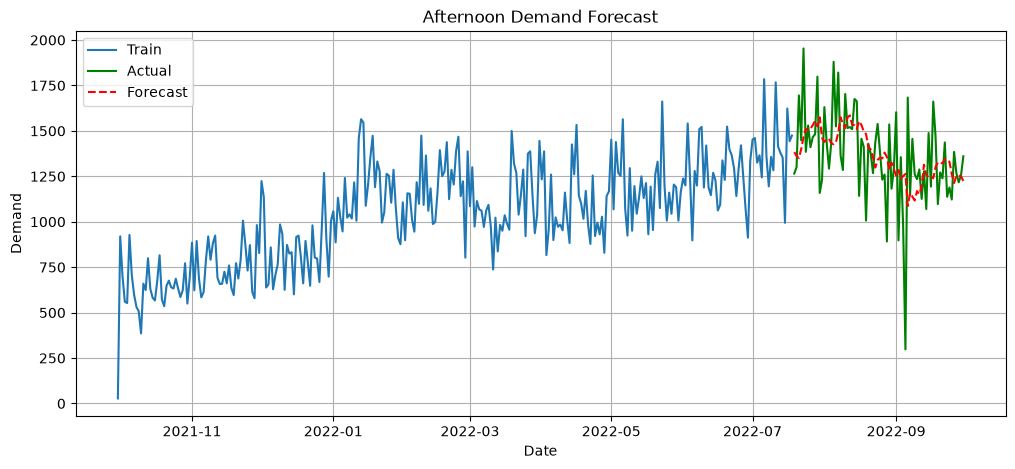

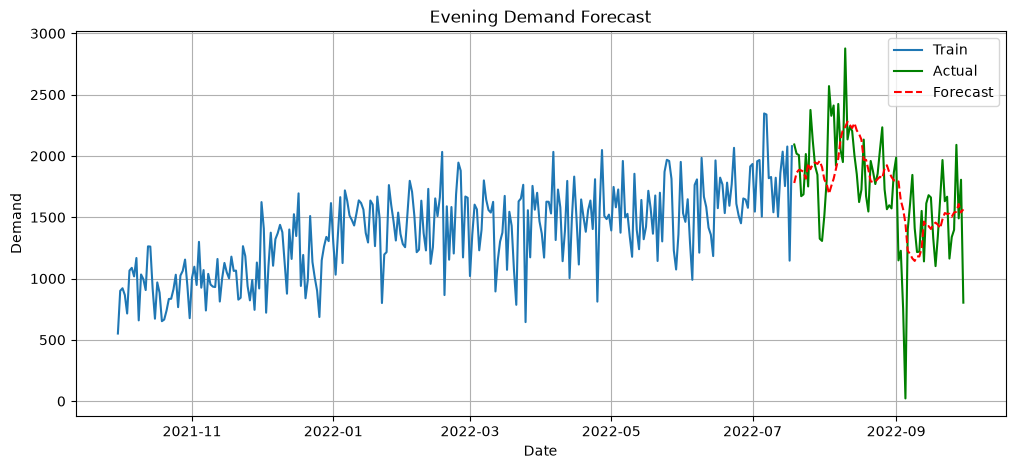

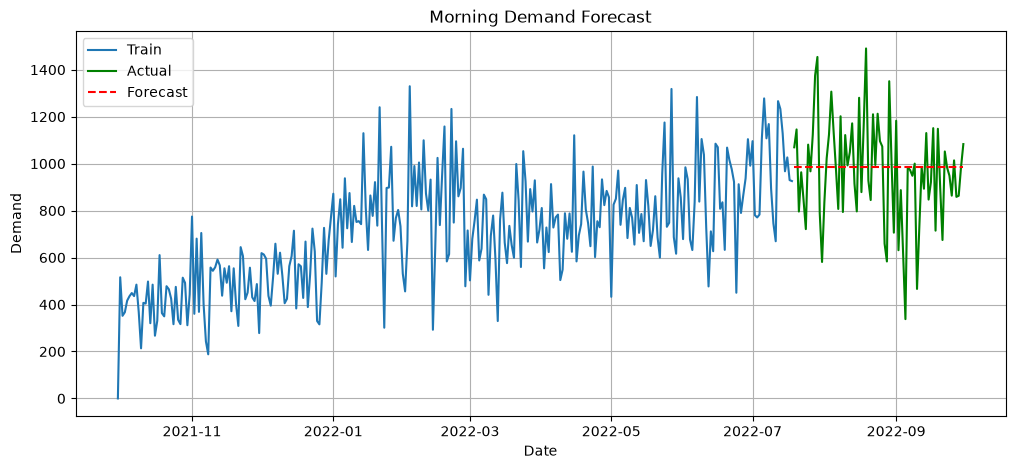

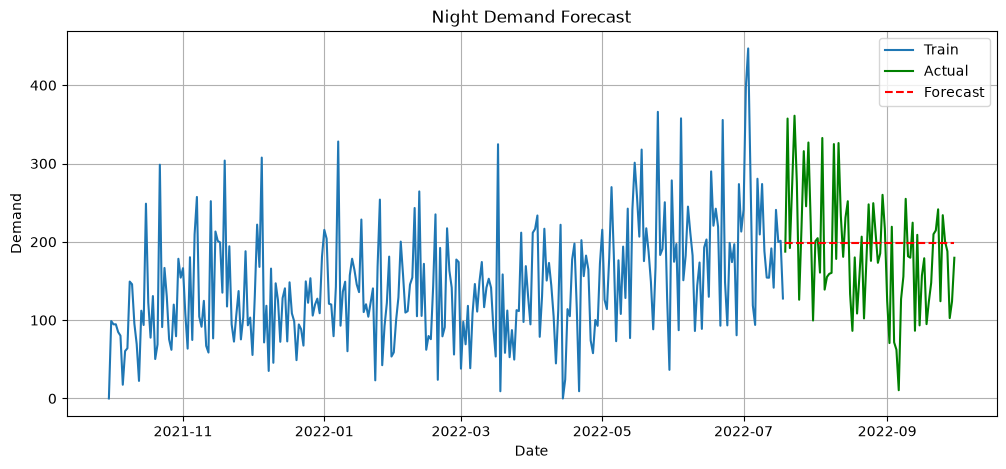

In [53]:
import matplotlib.pyplot as plt

for col in daily_period_demand.columns:

    series = daily_period_demand[col].dropna()

    train_size = int(len(series) * 0.8)

    train = series.iloc[:train_size]
    test = series.iloc[train_size:]

    # Use best model for each period
    if col in ['Afternoon', 'Evening']:

        history = list(train)
        preds = []

        for t in range(len(test)):
            pred = sum(history[-7:]) / 7
            preds.append(pred)
            history.append(test.iloc[t])

    else:  # Morning, Night

        model = SimpleExpSmoothing(
            train,
            initialization_method="heuristic"
        ).fit(optimized=True)

        preds = model.forecast(len(test))

    plt.figure(figsize=(12,5))

    plt.plot(train.index, train,
             label='Train')

    plt.plot(test.index, test,
             label='Actual',
             color='green')

    plt.plot(test.index, preds,
             label='Forecast',
             color='red',
             linestyle='--')

    plt.title(f'{col} Demand Forecast')
    plt.xlabel('Date')
    plt.ylabel('Demand')
    plt.legend()
    plt.grid(True)

    plt.show()

              MA_RMSE     ES_RMSE     HW_RMSE
Period                                       
Afternoon  243.940769  253.892337  326.244471
Evening    386.823951  447.453357  509.322355
Morning    224.053864  219.550909  247.016315
Night       73.780602   73.437481   83.011850


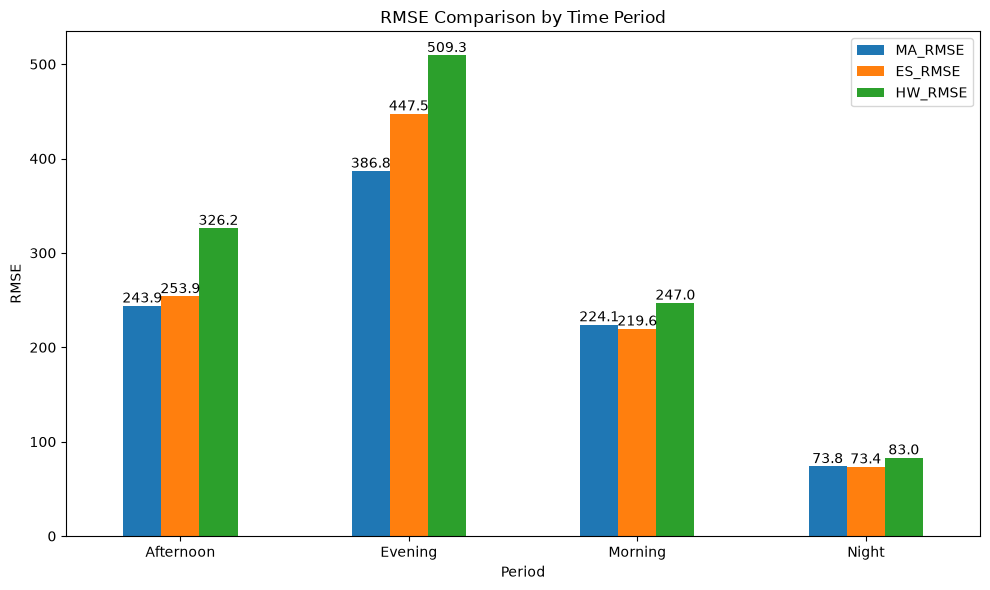

In [56]:
import matplotlib.pyplot as plt

rmse_plot = metrics_df.set_index('Period')[
    ['MA_RMSE', 'ES_RMSE', 'HW_RMSE']
]

print(rmse_plot)  # Verify values exist

ax = rmse_plot.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('RMSE Comparison by Time Period')
plt.ylabel('RMSE')
plt.xlabel('Period')
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')

plt.tight_layout()
plt.show()

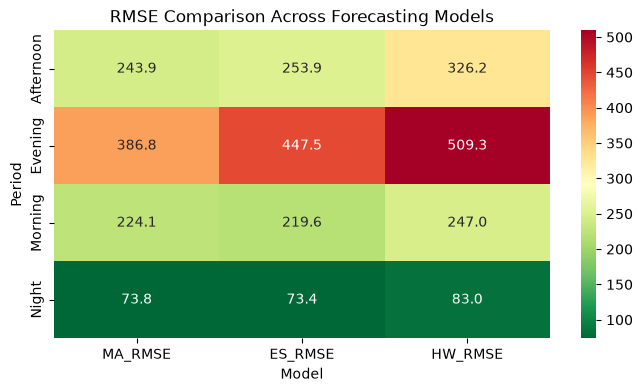

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

rmse_plot = metrics_df.set_index('Period')[
    ['MA_RMSE', 'ES_RMSE', 'HW_RMSE']
]

plt.figure(figsize=(8,4))

sns.heatmap(
    rmse_plot,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn_r'
)

plt.title('RMSE Comparison Across Forecasting Models')
plt.ylabel('Period')
plt.xlabel('Model')

plt.show()

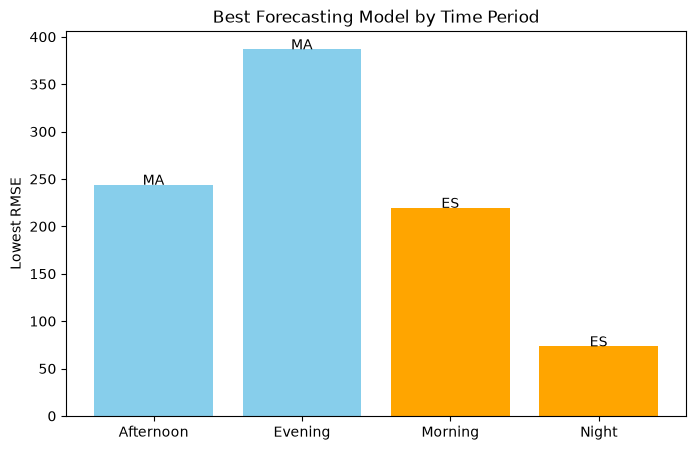

In [58]:
best_models = metrics_df.copy()

best_models['Best_Model'] = best_models[
    ['MA_RMSE','ES_RMSE','HW_RMSE']
].idxmin(axis=1)

colors = {
    'MA_RMSE':'skyblue',
    'ES_RMSE':'orange',
    'HW_RMSE':'green'
}

plt.figure(figsize=(8,5))

bars = plt.bar(
    best_models['Period'],
    best_models[
        ['MA_RMSE','ES_RMSE','HW_RMSE']
    ].min(axis=1),
    color=[colors[m] for m in best_models['Best_Model']]
)

plt.title('Best Forecasting Model by Time Period')
plt.ylabel('Lowest RMSE')

for bar, model in zip(bars, best_models['Best_Model']):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        model.replace('_RMSE',''),
        ha='center'
    )

plt.show()

In [59]:
import pickle

ma_model = {
    "window": 7,
    "last_7_values": series.iloc[-7:].tolist()
}

with open("moving_average_model.pkl", "wb") as f:
    pickle.dump(ma_model, f)

In [60]:
with open("moving_average_model.pkl", "rb") as f:
    ma_model = pickle.load(f)

forecast = sum(ma_model["last_7_values"]) / ma_model["window"]

print("Forecast:", forecast)

Forecast: 164.6457142857143
